# Episode-level evaluation, leakage-safe thresholding, and weather features

Builds on 0.3 (XGBoost breach classifier). Reuses the same SA1 data load, `will_breach` target (3h lookahead, 200 MW threshold), lag features, and data-gap guard.

1. **Diagnose misses** of the current best (11-feature XGBoost @ 0.5) on the 14 breach episodes in the 2026 test set.
2. **Pick a decision threshold without leakage**: tune on 2023-2024 train / 2025 validation, then evaluate that one fixed threshold on 2026 exactly once.
3. **Add weather features** (Adelaide, from Open-Meteo) and repeat the same leakage-safe threshold procedure.

No commits are made as part of this notebook.

In [1]:
import glob
from pathlib import Path

import numpy as np
import pandas as pd
import requests
import matplotlib.pyplot as plt
from xgboost import XGBClassifier
from sklearn.metrics import average_precision_score

## Data load, features, target (reused from 0.3)

In [2]:
all_files = glob.glob("../data/PRICE_AND_DEMAND_*_SA1.csv")
print(f"Found {len(all_files)} files")

df = pd.concat([pd.read_csv(f) for f in all_files], ignore_index=True)
df["SETTLEMENTDATE"] = pd.to_datetime(df["SETTLEMENTDATE"])
df = df[df["REGION"] == "SA1"].sort_values("SETTLEMENTDATE").reset_index(drop=True)
print(df.shape)

Found 12 files
(103680, 5)


In [3]:
df["hour"] = df["SETTLEMENTDATE"].dt.hour
df["day_of_week"] = df["SETTLEMENTDATE"].dt.dayofweek
df["day_of_year"] = df["SETTLEMENTDATE"].dt.dayofyear
df["hour_sin"] = np.sin(2 * np.pi * df["hour"] / 24)
df["hour_cos"] = np.cos(2 * np.pi * df["hour"] / 24)
df["doy_sin"] = np.sin(2 * np.pi * df["day_of_year"] / 365)
df["doy_cos"] = np.cos(2 * np.pi * df["day_of_year"] / 365)
df["dow_sin"] = np.sin(2 * np.pi * df["day_of_week"] / 7)
df["dow_cos"] = np.cos(2 * np.pi * df["day_of_week"] / 7)

In [4]:
INTERVALS_PER_HOUR = 12
THRESHOLD = 200
LOOKAHEAD = 3 * INTERVALS_PER_HOUR

df["will_breach"] = (
    df["TOTALDEMAND"].shift(-1).rolling(window=LOOKAHEAD, min_periods=LOOKAHEAD).min() < THRESHOLD
).astype(int)

df["demand_lag_30m"] = df["TOTALDEMAND"].shift(6)
df["demand_lag_1h"] = df["TOTALDEMAND"].shift(12)
df["demand_lag_2h"] = df["TOTALDEMAND"].shift(24)
df["demand_trend"] = df["TOTALDEMAND"] - df["demand_lag_2h"]
df["demand_rolling_std_2h"] = df["TOTALDEMAND"].rolling(24).std()

gap_minutes = df["SETTLEMENTDATE"].diff().dt.total_seconds() / 60
is_gap_nearby = (
    gap_minutes.rolling(LOOKAHEAD, min_periods=1).max().gt(5)
    | gap_minutes.shift(-LOOKAHEAD).rolling(LOOKAHEAD, min_periods=1).max().gt(5)
)
df = df[~is_gap_nearby.fillna(True)]
df = df.dropna().reset_index(drop=True)
df["year"] = df["SETTLEMENTDATE"].dt.year

print(df.shape)
print(f"Positive class rate: {df['will_breach'].mean():.3%}")

(103368, 21)
Positive class rate: 4.707%


## Shared helpers: episodes, alarm periods, episode-level evaluation, model fitting

`group_runs` merges consecutive flagged rows into (start, end) runs, closing any gap under an hour -- used for both breach episodes (`TOTALDEMAND < 200`) and alarm periods (`alarm == 1`), so a model that fires several times in quick succession over one event counts as *one* alarm period, not several.

In [5]:
def group_runs(flag, timestamps, merge_gap_minutes=60):
    """Boolean Series -> list of (start, end) runs, merging runs separated by < merge_gap_minutes."""
    flagged = pd.DataFrame({"time": timestamps, "flag": flag})
    flagged = flagged.loc[flagged["flag"], "time"].sort_values().reset_index(drop=True)
    if flagged.empty:
        return []
    gap = flagged.diff().dt.total_seconds() / 60
    group_id = (gap.isna() | (gap >= merge_gap_minutes)).cumsum()
    runs = flagged.groupby(group_id).agg(["min", "max"])
    return list(zip(runs["min"], runs["max"]))


def evaluate_episodes(eval_df, lead_window_hours=3):
    """eval_df needs SETTLEMENTDATE, TOTALDEMAND, alarm (0/1), optionally proba (score).

    Returns (episodes, alarm_periods, per-episode results DataFrame, summary dict).
    """
    episodes = group_runs(eval_df["TOTALDEMAND"] < 200, eval_df["SETTLEMENTDATE"])
    alarm_periods = group_runs(eval_df["alarm"].astype(bool), eval_df["SETTLEMENTDATE"])
    alarm_times = eval_df.loc[eval_df["alarm"].astype(bool), "SETTLEMENTDATE"]
    has_proba = "proba" in eval_df.columns

    rows = []
    episode_windows = []
    for onset, end in episodes:
        window_start = onset - pd.Timedelta(hours=lead_window_hours)
        episode_windows.append((window_start, end))

        warnings_before_onset = alarm_times[(alarm_times >= window_start) & (alarm_times < onset)]
        warned = not warnings_before_onset.empty
        lead_minutes = (
            (onset - warnings_before_onset.min()).total_seconds() / 60 if warned else np.nan
        )

        # How many separate (already-merged) alarm periods touch this one episode's window --
        # should be 0 or 1. A count >= 2 would mean two disjoint alarm bursts both belong to
        # the same real event, which needs to be counted as one true alarm, not two.
        n_overlapping_periods = sum(
            1 for p_start, p_end in alarm_periods if p_start <= end and p_end >= window_start
        )

        episode_rows = eval_df[(eval_df["SETTLEMENTDATE"] >= onset) & (eval_df["SETTLEMENTDATE"] <= end)]
        row = {
            "onset": onset,
            "end": end,
            "min_demand": episode_rows["TOTALDEMAND"].min(),
            "warned": warned,
            "lead_time_min": lead_minutes,
            "n_alarm_periods_overlapping": n_overlapping_periods,
        }
        if has_proba:
            window_scores = eval_df.loc[
                (eval_df["SETTLEMENTDATE"] >= window_start) & (eval_df["SETTLEMENTDATE"] < onset), "proba"
            ]
            row["peak_proba_pre_onset"] = window_scores.max() if not window_scores.empty else np.nan
        rows.append(row)

    results = pd.DataFrame(rows)

    def overlaps_any(period, windows):
        p_start, p_end = period
        return any(p_start <= w_end and p_end >= w_start for w_start, w_end in windows)

    false_alarm_periods = [p for p in alarm_periods if not overlaps_any(p, episode_windows)]

    n_episodes = len(episodes)
    n_warned = int(results["warned"].sum()) if n_episodes else 0
    summary = {
        "n_episodes": n_episodes,
        "n_warned": n_warned,
        "episode_recall": n_warned / n_episodes if n_episodes else np.nan,
        "median_lead_time_min": results.loc[results["warned"], "lead_time_min"].median() if n_warned else np.nan,
        "n_alarm_periods": len(alarm_periods),
        "n_false_alarm_periods": len(false_alarm_periods),
    }
    return episodes, alarm_periods, results, summary


def fit_xgb(train_df, feature_cols, target="will_breach", **overrides):
    X_train, y_train = train_df[feature_cols], train_df[target]
    scale_pos_weight = (y_train == 0).sum() / (y_train == 1).sum()
    params = dict(
        n_estimators=300,
        max_depth=4,
        learning_rate=0.05,
        subsample=0.8,
        colsample_bytree=0.8,
        scale_pos_weight=scale_pos_weight,
        eval_metric="aucpr",
        random_state=42,
    )
    params.update(overrides)
    model = XGBClassifier(**params)
    model.fit(X_train, y_train)
    return model

## Stage 0: reproduce the 0.3 best model (11 features, train 2023-2025, test 2026)

In [6]:
FEATURES = ["hour_sin", "hour_cos", "doy_sin", "doy_cos", "dow_sin", "dow_cos",
            "demand_lag_30m", "demand_lag_1h", "demand_lag_2h", "demand_trend",
            "demand_rolling_std_2h"]

train_full = df[df["year"] <= 2025]
test_2026 = df[df["year"] == 2026]

model_main = fit_xgb(train_full, FEATURES)
y_proba_main = model_main.predict_proba(test_2026[FEATURES])[:, 1]
y_pred_main = (y_proba_main >= 0.5).astype(int)

pr_auc_main = average_precision_score(test_2026["will_breach"], y_proba_main)
print(f"Train: {len(train_full)} rows (2023-2025), Test: {len(test_2026)} rows (2026)")
print(f"Row-level PR-AUC: {pr_auc_main:.3f}")

Train: 77807 rows (2023-2025), Test: 25561 rows (2026)
Row-level PR-AUC: 0.977


## Stage 1: diagnose misses

For each of the 2026 breach episodes: was it warned (alarm in the 3h before onset), how deep did demand actually go, and what was the model's peak probability in that pre-onset window?

In [7]:
eval_df_main = test_2026[["SETTLEMENTDATE", "TOTALDEMAND"]].reset_index(drop=True)
eval_df_main["alarm"] = y_pred_main
eval_df_main["proba"] = y_proba_main

episodes_main, alarm_periods_main, results_main, summary_main = evaluate_episodes(eval_df_main)

print(f"Episodes: {summary_main['n_episodes']}, warned: {summary_main['n_warned']} "
      f"({summary_main['episode_recall']:.1%})")
print(f"Median lead time (warned episodes): {summary_main['median_lead_time_min']:.0f} min")
print(f"Alarm periods: {summary_main['n_alarm_periods']}, "
      f"false-alarm periods: {summary_main['n_false_alarm_periods']}")

Episodes: 14, warned: 10 (71.4%)
Median lead time (warned episodes): 28 min
Alarm periods: 18, false-alarm periods: 5


In [8]:
display_cols = ["onset", "end", "min_demand", "peak_proba_pre_onset", "warned"]
episode_table = results_main[display_cols].copy()
episode_table.index = range(1, len(episode_table) + 1)
episode_table.index.name = "episode"
episode_table

,onset,end,min_demand,peak_proba_pre_onset,warned
episode,,,,,
1,2026-01-01 09:20:00,2026-01-01 15:45:00,-169.33,0.049363,False
2,2026-01-03 11:40:00,2026-01-03 11:40:00,152.20,0.849087,True
3,2026-01-03 13:40:00,2026-01-03 13:45:00,177.16,0.992912,True
4,2026-01-04 10:05:00,2026-01-04 14:25:00,23.07,0.481767,False
5,2026-01-10 13:15:00,2026-01-10 15:05:00,127.12,0.790017,True
6,2026-01-11 11:00:00,2026-01-11 15:50:00,-124.27,0.011169,False
7,2026-01-12 12:30:00,2026-01-12 12:40:00,192.52,0.828042,True
8,2026-01-13 13:10:00,2026-01-13 13:15:00,181.25,0.768358,True
9,2026-01-17 11:05:00,2026-01-17 13:45:00,112.06,0.849259,True


In [9]:
# Double-counting check: each episode's window should touch at most one merged alarm period.
overlap_counts = results_main["n_alarm_periods_overlapping"].value_counts().sort_index()
print("Alarm periods overlapping each episode's [onset-3h, end] window:")
print(overlap_counts)

if (results_main["n_alarm_periods_overlapping"] > 1).any():
    flagged = results_main[results_main["n_alarm_periods_overlapping"] > 1]
    print(f"\nWARNING: {len(flagged)} episode(s) touched by >1 alarm period -- inspect before trusting counts:")
    print(flagged[["onset", "end", "n_alarm_periods_overlapping"]])
else:
    print("\nOK: no episode is touched by more than one alarm period, so alarm-period counts "
          "(false-alarm periods included) are not double-counting hits on the same event.")

Alarm periods overlapping each episode's [onset-3h, end] window:
n_alarm_periods_overlapping
1    14
Name: count, dtype: int64

OK: no episode is touched by more than one alarm period, so alarm-period counts (false-alarm periods included) are not double-counting hits on the same event.


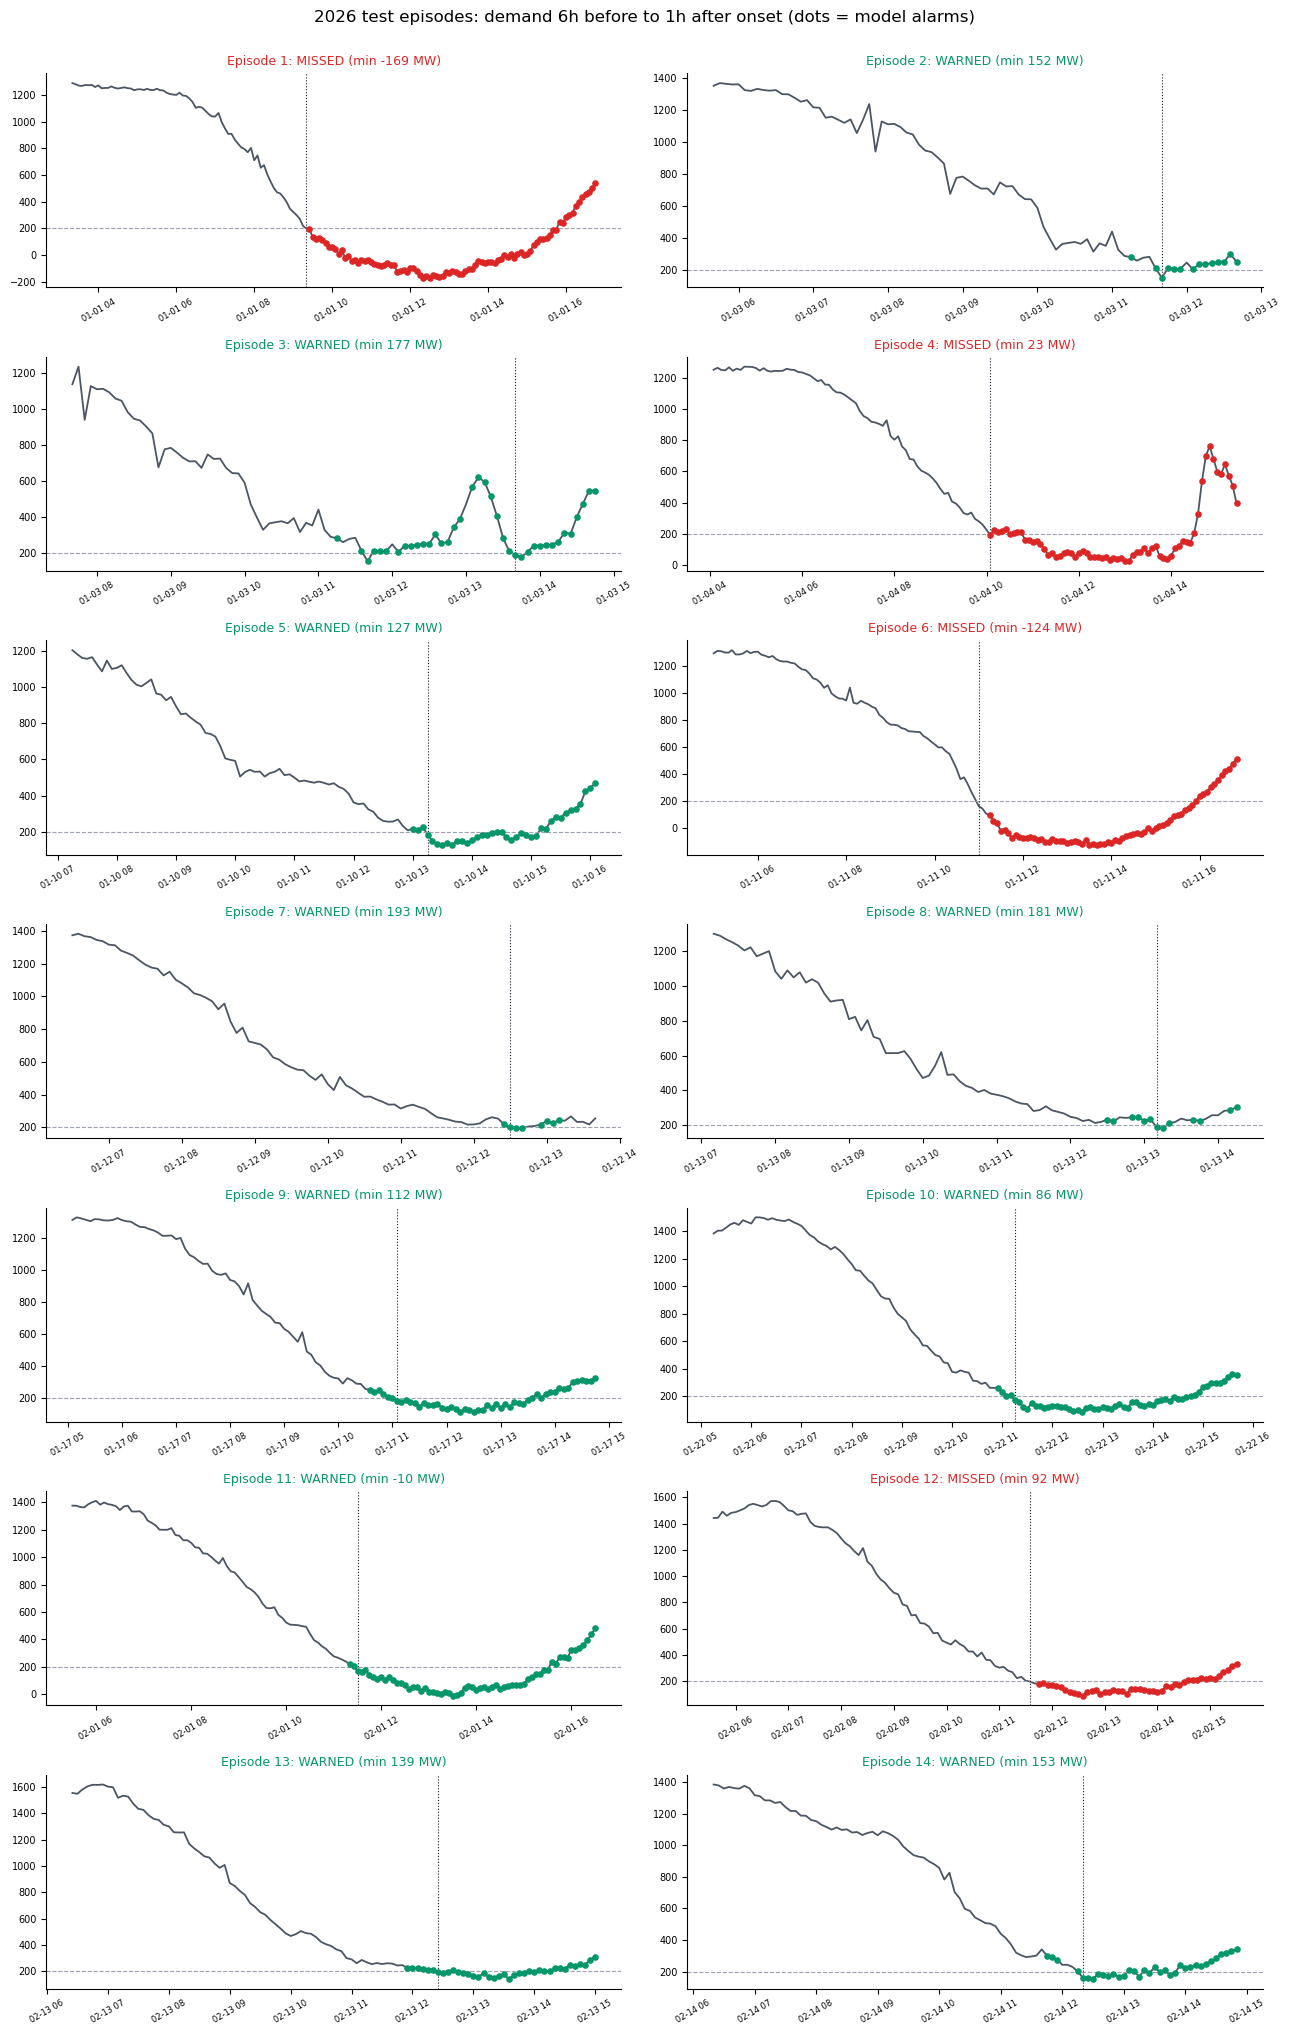

In [10]:
WARN_COLOR = "#059669"
MISS_COLOR = "#DC2626"
LINE_COLOR = "#4B5563"
THRESH_COLOR = "#9CA3AF"
ONSET_COLOR = "#111827"

n_episodes = len(results_main)
n_cols = 2
n_rows = -(-n_episodes // n_cols)
fig, axes = plt.subplots(n_rows, n_cols, figsize=(13, 2.9 * n_rows), sharey=False)
axes = np.atleast_1d(axes).flatten()

for i, ep in enumerate(results_main.itertuples()):
    ax = axes[i]
    window = eval_df_main[
        (eval_df_main["SETTLEMENTDATE"] >= ep.onset - pd.Timedelta(hours=6))
        & (eval_df_main["SETTLEMENTDATE"] <= ep.end + pd.Timedelta(hours=1))
    ]
    status_color = WARN_COLOR if ep.warned else MISS_COLOR

    ax.plot(window["SETTLEMENTDATE"], window["TOTALDEMAND"], color=LINE_COLOR, linewidth=1.3)
    ax.axhline(200, color=THRESH_COLOR, linestyle="--", linewidth=0.8)
    ax.axvline(ep.onset, color=ONSET_COLOR, linestyle=":", linewidth=0.8)

    alarmed = window[window["alarm"] == 1]
    ax.scatter(alarmed["SETTLEMENTDATE"], alarmed["TOTALDEMAND"], color=status_color, s=14, zorder=3)

    ax.set_title(
        f"Episode {i + 1}: {'WARNED' if ep.warned else 'MISSED'} (min {ep.min_demand:.0f} MW)",
        fontsize=9, color=status_color,
    )
    ax.tick_params(axis="x", labelrotation=30, labelsize=6)
    ax.tick_params(axis="y", labelsize=7)
    ax.spines[["top", "right"]].set_visible(False)

for ax in axes[n_episodes:]:
    ax.axis("off")

fig.suptitle("2026 test episodes: demand 6h before to 1h after onset (dots = model alarms)", y=1.0, fontsize=12)
fig.tight_layout()
plt.show()

## Stage 2: pick a decision threshold without touching 2026

Train on 2023-2024 only, sweep thresholds on 2025 (validation), pick the threshold with >=90% episode recall on 2025 and the fewest false-alarm periods (ties broken toward the lower threshold, which tends to warn earlier). That single threshold is then evaluated on 2026 exactly once, reusing `model_main` (already trained on 2023-2025 in Stage 0) -- no further tuning happens on 2026.

In [11]:
train_2324 = df[df["year"].isin([2023, 2024])]
val_2025 = df[df["year"] == 2025]

model_2324 = fit_xgb(train_2324, FEATURES)
proba_val = model_2324.predict_proba(val_2025[FEATURES])[:, 1]

thresholds = np.round(np.arange(0.10, 0.71, 0.05), 2)
sweep_rows = []
for t in thresholds:
    eval_df_val = val_2025[["SETTLEMENTDATE", "TOTALDEMAND"]].reset_index(drop=True)
    eval_df_val["alarm"] = (proba_val >= t).astype(int)
    _, _, _, summary = evaluate_episodes(eval_df_val)
    sweep_rows.append({"threshold": t, **summary})

sweep_df = pd.DataFrame(sweep_rows)
sweep_df

,threshold,n_episodes,n_warned,episode_recall,median_lead_time_min,n_alarm_periods,n_false_alarm_periods
0,0.10,23,15,0.652174,20.0,41,19
1,0.15,23,12,0.521739,27.5,40,18
2,0.20,23,12,0.521739,20.0,43,20
3,0.25,23,12,0.521739,20.0,44,21
4,0.30,23,11,0.478261,20.0,43,20
5,0.35,23,9,0.391304,35.0,40,17
6,0.40,23,9,0.391304,35.0,41,18
7,0.45,23,9,0.391304,35.0,39,16
8,0.50,23,8,0.347826,27.5,38,15
9,0.55,23,8,0.347826,27.5,38,14


In [12]:
def pick_threshold(sweep, min_recall=0.9):
    candidates = sweep[sweep["episode_recall"] >= min_recall]
    if candidates.empty:
        print(f"No threshold reached {min_recall:.0%} episode recall on validation; "
              f"falling back to the threshold(s) with the highest recall achieved.")
        candidates = sweep[sweep["episode_recall"] == sweep["episode_recall"].max()]
    chosen = candidates.sort_values(["n_false_alarm_periods", "threshold"]).iloc[0]
    return chosen

chosen = pick_threshold(sweep_df)
chosen_threshold = float(chosen["threshold"])
print(f"Chosen threshold (validated on 2025): {chosen_threshold}")
print(f"2025 validation @ this threshold: recall {chosen['episode_recall']:.1%} "
      f"({int(chosen['n_warned'])}/{int(chosen['n_episodes'])}), "
      f"median lead {chosen['median_lead_time_min']:.0f} min, "
      f"false-alarm periods {int(chosen['n_false_alarm_periods'])}")

No threshold reached 90% episode recall on validation; falling back to the threshold(s) with the highest recall achieved.
Chosen threshold (validated on 2025): 0.1
2025 validation @ this threshold: recall 65.2% (15/23), median lead 20 min, false-alarm periods 19


In [13]:
# One-shot evaluation on 2026 at the fixed, validated threshold. model_main was already
# trained on 2023-2025 in Stage 0, so this reuses it rather than retraining -- 2026 is
# untouched by any tuning decision.
eval_df_b = eval_df_main.copy()
eval_df_b["alarm"] = (y_proba_main >= chosen_threshold).astype(int)

episodes_b, alarm_periods_b, results_b, summary_b = evaluate_episodes(eval_df_b)

print(f"2026 test @ threshold {chosen_threshold}: recall {summary_b['episode_recall']:.1%} "
      f"({summary_b['n_warned']}/{summary_b['n_episodes']}), "
      f"median lead {summary_b['median_lead_time_min']:.0f} min, "
      f"false-alarm periods {summary_b['n_false_alarm_periods']}")

2026 test @ threshold 0.1: recall 85.7% (12/14), median lead 42 min, false-alarm periods 5


## Stage 3: weather features

Fetch hourly historical weather for Adelaide (shortwave radiation, cloud cover, 2m temperature) from the Open-Meteo archive API, cached to `data/adelaide_weather.csv`. AEMO's `SETTLEMENTDATE` is fixed NEM time (AEST, UTC+10, no daylight saving), which does **not** match Adelaide's local clock (ACST/ACDT, UTC+9:30/+10:30) -- so instead of trying to track South Australia's DST switches, everything is aligned in UTC: `settlement_utc = SETTLEMENTDATE - 10h`, and the weather is fetched and merged in UTC. The fetch spans the full date range of the price/demand data (2023-01 to 2026-07), which covers all of the Dec-Feb "summer" windows the demand data is built from, plus the extra 2026 winter rows -- so no test rows are silently dropped for being outside the weather window.

In [14]:
WEATHER_CACHE_PATH = Path("../data/adelaide_weather.csv")
ADELAIDE_LAT, ADELAIDE_LON = -34.9285, 138.6007

if WEATHER_CACHE_PATH.exists():
    weather = pd.read_csv(WEATHER_CACHE_PATH, parse_dates=["time_utc"])
    print(f"Loaded cached weather data: {weather.shape}")
else:
    start_date = df["SETTLEMENTDATE"].min().date().isoformat()
    end_date = df["SETTLEMENTDATE"].max().date().isoformat()
    print(f"Fetching Open-Meteo archive weather for Adelaide, {start_date} to {end_date}...")

    response = requests.get(
        "https://archive-api.open-meteo.com/v1/archive",
        params={
            "latitude": ADELAIDE_LAT,
            "longitude": ADELAIDE_LON,
            "start_date": start_date,
            "end_date": end_date,
            "hourly": "shortwave_radiation,cloudcover,temperature_2m",
            "timezone": "UTC",
        },
        timeout=60,
    )
    response.raise_for_status()
    hourly = response.json()["hourly"]

    weather = pd.DataFrame({
        "time_utc": pd.to_datetime(hourly["time"]),
        "shortwave_radiation": hourly["shortwave_radiation"],
        "cloudcover": hourly["cloudcover"],
        "temperature_2m": hourly["temperature_2m"],
    })
    weather.to_csv(WEATHER_CACHE_PATH, index=False)
    print(f"Cached weather data to {WEATHER_CACHE_PATH}: {weather.shape}")

weather.head()

Loaded cached weather data: (30672, 4)


,time_utc,shortwave_radiation,cloudcover,temperature_2m
0,2023-01-01 00:00:00,735.0,0,29.0
1,2023-01-01 01:00:00,895.0,0,30.9
2,2023-01-01 02:00:00,1005.0,0,31.2
3,2023-01-01 03:00:00,1053.0,0,31.7
4,2023-01-01 04:00:00,1052.0,0,32.3


In [15]:
WEATHER_FEATURES = ["shortwave_radiation", "cloudcover", "temperature_2m"]

df["settlement_utc"] = df["SETTLEMENTDATE"] - pd.Timedelta(hours=10)
weather_sorted = weather.sort_values("time_utc").reset_index(drop=True)

df_weather = pd.merge_asof(
    df.sort_values("settlement_utc"),
    weather_sorted,
    left_on="settlement_utc",
    right_on="time_utc",
    direction="backward",
).sort_values("SETTLEMENTDATE").reset_index(drop=True)

n_before = len(df_weather)
df_weather = df_weather.dropna(subset=WEATHER_FEATURES).reset_index(drop=True)
print(f"Rows before/after dropping missing weather: {n_before} -> {len(df_weather)}")
print(df_weather["year"].value_counts().sort_index())

Rows before/after dropping missing weather: 103368 -> 103273
year
2023    25728
2024    26136
2025    25848
2026    25561
Name: count, dtype: int64


In [16]:
FEATURES_WEATHER = FEATURES + WEATHER_FEATURES

train_2324_w = df_weather[df_weather["year"].isin([2023, 2024])]
val_2025_w = df_weather[df_weather["year"] == 2025]
train_full_w = df_weather[df_weather["year"] <= 2025]
test_2026_w = df_weather[df_weather["year"] == 2026]

model_2324_w = fit_xgb(train_2324_w, FEATURES_WEATHER)
proba_val_w = model_2324_w.predict_proba(val_2025_w[FEATURES_WEATHER])[:, 1]

sweep_rows_w = []
for t in thresholds:
    eval_df_val_w = val_2025_w[["SETTLEMENTDATE", "TOTALDEMAND"]].reset_index(drop=True)
    eval_df_val_w["alarm"] = (proba_val_w >= t).astype(int)
    _, _, _, summary = evaluate_episodes(eval_df_val_w)
    sweep_rows_w.append({"threshold": t, **summary})

sweep_df_w = pd.DataFrame(sweep_rows_w)
sweep_df_w

,threshold,n_episodes,n_warned,episode_recall,median_lead_time_min,n_alarm_periods,n_false_alarm_periods
0,0.10,23,15,0.652174,15.0,38,16
1,0.15,23,13,0.565217,20.0,37,15
2,0.20,23,11,0.478261,20.0,37,15
3,0.25,23,10,0.434783,27.5,38,15
4,0.30,23,10,0.434783,27.5,36,13
5,0.35,23,9,0.391304,35.0,36,13
6,0.40,23,9,0.391304,35.0,34,11
7,0.45,23,9,0.391304,35.0,35,12
8,0.50,23,9,0.391304,35.0,36,13
9,0.55,23,9,0.391304,20.0,36,13


In [17]:
chosen_w = pick_threshold(sweep_df_w)
chosen_threshold_weather = float(chosen_w["threshold"])
print(f"Chosen threshold with weather features (validated on 2025): {chosen_threshold_weather}")
print(f"2025 validation @ this threshold: recall {chosen_w['episode_recall']:.1%} "
      f"({int(chosen_w['n_warned'])}/{int(chosen_w['n_episodes'])}), "
      f"median lead {chosen_w['median_lead_time_min']:.0f} min, "
      f"false-alarm periods {int(chosen_w['n_false_alarm_periods'])}")

No threshold reached 90% episode recall on validation; falling back to the threshold(s) with the highest recall achieved.
Chosen threshold with weather features (validated on 2025): 0.1
2025 validation @ this threshold: recall 65.2% (15/23), median lead 15 min, false-alarm periods 16


In [18]:
# Final model, retrained on 2023-2025 (weather-covered rows only), evaluated once on 2026.
model_weather_final = fit_xgb(train_full_w, FEATURES_WEATHER)
y_proba_weather_test = model_weather_final.predict_proba(test_2026_w[FEATURES_WEATHER])[:, 1]

pr_auc_weather = average_precision_score(test_2026_w["will_breach"], y_proba_weather_test)

eval_df_c = test_2026_w[["SETTLEMENTDATE", "TOTALDEMAND"]].reset_index(drop=True)
eval_df_c["alarm"] = (y_proba_weather_test >= chosen_threshold_weather).astype(int)

episodes_c, alarm_periods_c, results_c, summary_c = evaluate_episodes(eval_df_c)

print(f"Weather-covered 2026 test rows: {len(test_2026_w)} (vs {len(test_2026)} without the weather restriction)")
print(f"Row-level PR-AUC: {pr_auc_weather:.3f}")
print(f"Recall {summary_c['episode_recall']:.1%} ({summary_c['n_warned']}/{summary_c['n_episodes']}), "
      f"median lead {summary_c['median_lead_time_min']:.0f} min, "
      f"false-alarm periods {summary_c['n_false_alarm_periods']}")

Weather-covered 2026 test rows: 25561 (vs 25561 without the weather restriction)
Row-level PR-AUC: 0.974
Recall 85.7% (12/14), median lead 38 min, false-alarm periods 6


## Final comparison

In [19]:
comparison_final = pd.DataFrame([
    {
        "Model": "(a) 11-feature XGBoost @ 0.5",
        "Row-level PR-AUC": pr_auc_main,
        "Episodes (n)": summary_main["n_episodes"],
        "Warned": summary_main["n_warned"],
        "Episode recall": summary_main["episode_recall"],
        "Median lead (min)": summary_main["median_lead_time_min"],
        "False-alarm periods": summary_main["n_false_alarm_periods"],
    },
    {
        "Model": f"(b) same model @ validated threshold {chosen_threshold}",
        "Row-level PR-AUC": pr_auc_main,
        "Episodes (n)": summary_b["n_episodes"],
        "Warned": summary_b["n_warned"],
        "Episode recall": summary_b["episode_recall"],
        "Median lead (min)": summary_b["median_lead_time_min"],
        "False-alarm periods": summary_b["n_false_alarm_periods"],
    },
    {
        "Model": f"(c) + weather @ validated threshold {chosen_threshold_weather}",
        "Row-level PR-AUC": pr_auc_weather,
        "Episodes (n)": summary_c["n_episodes"],
        "Warned": summary_c["n_warned"],
        "Episode recall": summary_c["episode_recall"],
        "Median lead (min)": summary_c["median_lead_time_min"],
        "False-alarm periods": summary_c["n_false_alarm_periods"],
    },
]).set_index("Model")

comparison_final.round(3)

,Row-level PR-AUC,Episodes (n),Warned,Episode recall,Median lead (min),False-alarm periods
Model,,,,,,
(a) 11-feature XGBoost @ 0.5,0.977,14,10,0.714,27.5,5
(b) same model @ validated threshold 0.1,0.977,14,12,0.857,42.5,5
(c) + weather @ validated threshold 0.1,0.974,14,12,0.857,37.5,6


**Read the episode-level columns with the `Episodes (n)` count in view.** There are only 14 breach episodes in the full 2026 test set, and fewer still in the weather-restricted subset (model (c)) -- at that sample size, one extra warned or missed episode swings the recall percentage by several points and the median lead time is a median of a handful of numbers. Row-level PR-AUC is far more statistically stable (tens of thousands of rows) and is a better signal for ranking the models; the episode-level numbers should be read as illustrative, not as tight estimates.

## Export: model predictions for Tableau dashboard

Exports the 2026 test-set predictions from `model_main` (trained on 2023-2025, 11 features) at the leakage-safe validated threshold (`chosen_threshold`, selected on 2025 in Stage 2 above) for use in an external Tableau dashboard. Row-for-row the same predictions already evaluated as `summary_b` -- this cell only reshapes and writes them to CSV.

In [20]:
predictions_export = pd.DataFrame({
    "SETTLEMENTDATE": test_2026["SETTLEMENTDATE"].reset_index(drop=True),
    "TOTALDEMAND": test_2026["TOTALDEMAND"].reset_index(drop=True),
    "predicted_probability": y_proba_main,
    "will_breach": test_2026["will_breach"].reset_index(drop=True),
})
predictions_export["alarm_raised"] = (predictions_export["predicted_probability"] >= chosen_threshold).astype(int)
predictions_export = predictions_export[
    ["SETTLEMENTDATE", "TOTALDEMAND", "predicted_probability", "alarm_raised", "will_breach"]
]

export_path = Path("../data/dashboard_model_predictions.csv")
predictions_export.to_csv(export_path, index=False)

print(f"Wrote {len(predictions_export)} rows to {export_path}")
print(f"Columns: {predictions_export.columns.tolist()}")
print(f"Validated threshold used: {chosen_threshold}")

Wrote 25561 rows to ../data/dashboard_model_predictions.csv
Columns: ['SETTLEMENTDATE', 'TOTALDEMAND', 'predicted_probability', 'alarm_raised', 'will_breach']
Validated threshold used: 0.1
